# L2-Arctic-plus: nguồn công bố và kiểm tra dữ liệu

[Bài báo Findings of EACL 2026](https://aclanthology.org/2026.findings-eacl.190/) · [Repo tác giả](https://github.com/zoeyada/ALMs4Learning).

Nguồn này có hướng dẫn sửa phát âm tiếng Anh; khác với L2-ARCTIC gốc chỉ có nhãn âm vị. Nhánh Qwen có thể dùng nhãn hướng dẫn công bố thay cho việc yêu cầu người dùng duyệt toàn bộ 300 template của project. Notebook này kiểm tra **nguồn dữ liệu**, chưa train model hoặc khẳng định chất lượng từng hướng dẫn.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/audit_l2arctic_plus.py').is_file())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from scripts.audit_l2arctic_plus import audit
SOURCE=ROOT/'data/external/l2arctic-plus/e8c7684c545d94f2419fc4621e745236c192a353'
report=audit(SOURCE)
print('Commit:',report['source_commit'])
print('Checksum đã kiểm tra:',report['source_checksums_verified'])
print('Đường dẫn:',SOURCE)

Commit: e8c7684c545d94f2419fc4621e745236c192a353
Checksum đã kiểm tra: True
Đường dẫn: D:\NCC\MDD\data\external\l2arctic-plus\e8c7684c545d94f2419fc4621e745236c192a353


## 1. Nhãn nào đã được người kiểm tra?

Mục 3.2: lời hướng dẫn của 900 mẫu đánh giá được GPT-4o tạo rồi ba người kiểm tra. Mục 6.1: lời hướng dẫn của bộ train được GPT-4o tạo **không có bước kiểm tra thủ công**. Nhãn âm vị đầu vào đến từ L2-ARCTIC. `regeneration` chỉ ghi việc tạo lại, không phải chứng nhận từng mẫu đã được người duyệt.

[Bài báo, mục 3.2 và 6.1](https://aclanthology.org/2026.findings-eacl.190.pdf). Không gắn tên giáo viên hoặc `approved=true` do project tự tạo cho các nhãn công bố.

In [2]:
summary=pd.DataFrame({name:{'records':part['records'],'speakers':len(part['speakers']),'unique_prompts':part['unique_prompts'],'feedback_pairs':part['feedback_pairs'],'no_flagged_word_feedback':part['no_flagged_word_feedback']} for name,part in report['partitions'].items()}).T
display(summary)
display(pd.DataFrame([{'split':'train','feedback':'GPT-4o, không kiểm tra thủ công (mục 6.1)'},{'split':'test','feedback':'GPT-4o + ba người kiểm tra (mục 3.2)'}]))
print('README và file thực tế:',report['readme_record_count_discrepancy'])

,records,speakers,unique_prompts,feedback_pairs,no_flagged_word_feedback
train,2699,18,329,13726,105
test,900,6,304,4212,31


,split,feedback
0,train,"GPT-4o, không kiểm tra thủ công (mục 6.1)"
1,test,GPT-4o + ba người kiểm tra (mục 3.2)


README và file thực tế: {'readme_train': 1699, 'actual_train': 2699}


## 2. Split công bố

Không có utterance hay người nói trùng giữa train/test. Có câu đọc chung: đây là đánh giá trên người nói khác, không phải trên câu hoàn toàn mới. Khi train, validation phải được tách từ tập train; giữ nguyên test. Vì tập Plus xây từ L2-ARCTIC, không coi đây là corpus âm thanh độc lập với dữ liệu MDD đã dùng trước đó.

Giao train/test: {'utterances': 0, 'speakers': [], 'normalized_reference_prompts': 300}


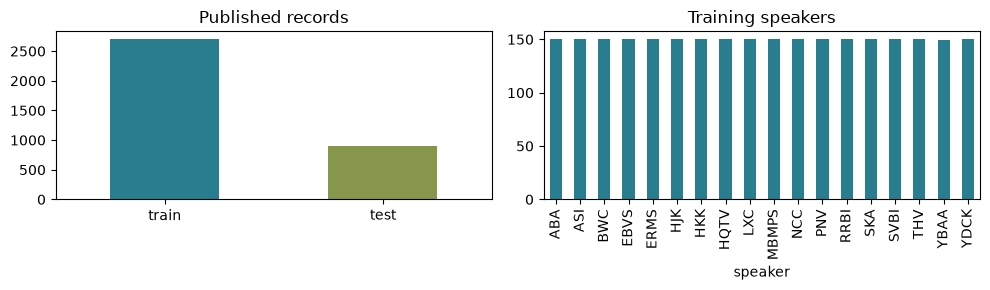

In [3]:
print('Giao train/test:',report['official_train_test_overlap'])
fig,axes=plt.subplots(1,2,figsize=(10,3))
summary['records'].plot.bar(ax=axes[0],color=['#287d8e','#86974c'],rot=0,title='Published records')
speakers=pd.DataFrame(report['partitions']['train']['speakers'].items(),columns=['speaker','records'])
speakers.plot.bar(x='speaker',y='records',ax=axes[1],legend=False,title='Training speakers',color='#287d8e')
fig.tight_layout(); display(fig); plt.close(fig)

## 3. Xem định dạng hướng dẫn gốc

`annotation_info` chứa nhãn âm vị; `mis_exp_sug` chứa cặp issue/suggestion theo từ. Đây là dữ liệu có sẵn từ tác giả, chưa phải JSON assessment→feedback và tiếng Việt của demo. Chuyển đổi phải giữ từ/âm/loại lỗi khớp nhãn, ghi lại nguồn và mọi bản dịch; không xem bản dịch tiếng Việt là nhãn gốc đã được tác giả duyệt.

In [4]:
train=json.loads((SOURCE/'data/L2-Arctic-plus/train_data.json').read_text(encoding='utf-8'))
example=train[0]
print('Câu:',example['text'])
print('Audio gốc:',example['audio_path'])
print('Nhãn âm vị:',json.dumps(example['annotation_info'],ensure_ascii=False))
display(pd.DataFrame([{'word':word,**pair} for word,pairs in example['mis_exp_sug'].items() for pair in pairs]))

Câu: You're joking me sir the other managed to articulate
Audio gốc: ./data/L2-Arctic-plus/l2arctic_release_v5.0/ABA/wav/arctic_a0501.wav
Nhãn âm vị: {"you're": ["Y", "UH", "R"], "joking": ["JH, ZH, s", "OW", "K", "IH", "NG", "sil, G, a", "sil, AH, a"], "me": ["M", "IY"], "sir": ["S", "ER, err, s"], "the": ["DH", "AH"], "other": ["AH", "DH, Z, s", "ER, err, s"], "managed": ["M", "AE", "N", "IH", "JH, ZH, s", "D"], "to": ["T", "UW"], "articulate": ["AA", "R, R*, s", "T", "IH", "K", "Y", "AH", "L", "EY, EH, s", "T"]}


,word,issue,suggestion
0,joking,"""JH"" was replaced with ""ZH"", indicating a subs...","Practice the difference between /JH/ as in ""JO..."
1,joking,"An extra ""G"" sound was added, indicating an ad...","Focus on stopping after the /NG/ as in ""KING"" ..."
2,joking,"An extra ""AH"" sound was added, indicating an a...",Avoid adding extra vowel sounds after completi...
3,sir,"Unclear pronunciation, ""ER"" perceived with unc...","Practice /ER/ as in ""SIR"" (/S ER/) to add clarity"
4,other,"""DH"" was replaced with ""Z"", indicating a subst...","Practice unvoiced /DH/ as in ""THIS"" (/DH IH S/..."
5,other,"Unclear pronunciation, ""ER"" perceived with unc...","Practice /ER/ as in ""HER"" (/HH ER/) for more d..."
6,managed,"""JH"" was replaced with ""ZH"", indicating a subs...","Practice the distinction between /JH/ as in ""J..."
7,articulate,"""R"" was replaced with a foreign-accented ""R*"",...","Practice the American /R/ sound as in ""RED"" (/..."
8,articulate,"""EY"" was replaced with ""EH"", indicating a subs...","Practice the distinction between /EY/ as in ""D..."


## 4. Trạng thái thực tế

Đã tải annotation từ repo chính thức, ghim commit và kiểm tra SHA-256. Chưa train bằng Plus; không dùng 900 mẫu test để train. Hướng dẫn tiếng Việt cần bước chuyển đổi/dịch có provenance. Lệnh dưới kiểm tra lại nguồn, không gọi LLM/ai33.

In [5]:
print(r'.venv\Scripts\python.exe -X utf8 scripts/audit_l2arctic_plus.py')
print('Train Plus đã chạy:',report['training_started'])
print('Report:',ROOT/'data/generated/setup/l2arctic_plus_audit.json')

.venv\Scripts\python.exe -X utf8 scripts/audit_l2arctic_plus.py
Train Plus đã chạy: False
Report: D:\NCC\MDD\data\generated\setup\l2arctic_plus_audit.json
